# Prediksi Performance Level Siswa — Klasifikasi Multi-Kelas (4 kelas)

Notebook ini melakukan EDA, feature engineering, dan pemodelan untuk memprediksi
`target` (performance level 0-3) menggunakan LightGBM, XGBoost, dan TabPFN.

**Struktur:**
1. Setup & EDA
2. Feature Engineering
3. Preprocessing
4. Modeling (LightGBM, XGBoost, TabPFN, Ensemble)
5. Evaluasi
6. Submission


## 1. Setup & EDA

In [1]:

# --- Install dependencies yang mungkin belum ada (aman dijalankan berkali-kali) ---
import importlib, subprocess, sys

def ensure(pkg, import_name=None):
    import_name = import_name or pkg
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

for pkg, mod in [("lightgbm", "lightgbm"), ("xgboost", "xgboost"),
                  ("optuna", "optuna"), ("tabpfn", "tabpfn")]:
    ensure(pkg, mod)

print("Semua dependency siap.")


Semua dependency siap.


In [2]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix, classification_report

RANDOM_STATE = 42
N_SPLITS = 5
N_CLASSES = 4

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

pd.set_option("display.max_columns", 100)


### 1.1 Load data

In [3]:

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
sample_sub = pd.read_csv("data/sample_submission.csv")

print("train shape:", train.shape)
print("test shape :", test.shape)
print("sample_submission shape:", sample_sub.shape)

train.head()


train shape: (3200, 43)
test shape : (800, 42)
sample_submission shape: (800, 2)


,id,nilai_minggu_01,nilai_minggu_02,nilai_minggu_03,nilai_minggu_04,nilai_minggu_05,nilai_minggu_06,nilai_minggu_07,nilai_minggu_08,nilai_minggu_09,nilai_minggu_10,nilai_minggu_11,nilai_minggu_12,skor_motivasi,skor_kedisiplinan,aktivitas_hari_01,aktivitas_hari_02,aktivitas_hari_03,aktivitas_hari_04,aktivitas_hari_05,aktivitas_hari_06,aktivitas_hari_07,aktivitas_hari_08,aktivitas_hari_09,aktivitas_hari_10,aktivitas_hari_11,aktivitas_hari_12,aktivitas_hari_13,aktivitas_hari_14,aktivitas_hari_15,aktivitas_hari_16,tugas_selesai,tugas_diberikan,kelas,urutan_ujian,skor_tryout,jarak_rumah_km,skor_ekstrakurikuler,indeks_kehadiran,skor_literasi,jumlah_saudara,skor_minat_belajar,target
0,0,2.6,6.4,3.6,1.0,4.4,8.5,-4.0,-0.1,-4.7,1.0,-4.7,-5.1,-0.53,-0.33,64.3,42.7,42.4,65.4,77.6,61.2,36.8,34.4,51.8,89.6,55.2,44.7,42.0,46.7,69.2,46.9,8,9,114,0.0817,72.3,0.46,0.00,-0.38,-0.24,-0.70,-0.62,3
1,1,-0.3,5.7,1.7,1.3,6.1,5.8,-0.1,-3.8,-3.1,-3.1,-1.0,1.0,-2.24,1.82,27.8,51.6,53.6,56.4,40.7,68.0,66.4,30.5,51.8,74.3,61.4,41.6,38.7,72.0,31.7,32.6,46,85,301,0.3388,41.4,-1.29,0.51,0.86,-0.70,-1.04,2.15,1
2,2,-4.8,-0.8,-3.5,-6.3,-3.7,-1.5,10.7,8.7,5.8,5.2,7.2,9.9,-1.18,-1.34,33.9,50.4,50.0,36.4,73.0,66.4,36.6,62.2,60.5,35.9,49.0,63.3,43.7,47.2,53.5,44.9,23,75,28,0.0517,73.2,-0.03,-0.33,0.14,0.80,0.26,-0.57,3
3,4,4.7,1.1,2.1,0.2,1.9,1.4,-0.5,-0.3,0.5,-1.4,-1.2,3.6,-0.60,0.69,51.0,48.0,36.5,31.8,53.0,60.7,76.7,65.1,51.1,39.0,36.4,41.9,49.1,56.2,70.6,64.5,95,110,580,0.0310,59.1,-0.20,0.24,1.68,-0.44,1.32,-0.64,1
4,5,13.3,3.5,3.4,4.1,6.2,8.7,-5.0,-6.1,-5.2,-8.2,-7.1,-6.6,-1.19,-0.67,59.2,43.0,43.6,64.6,57.7,42.2,57.7,57.7,47.9,37.2,62.3,77.4,36.5,42.2,58.5,52.8,24,32,127,0.5829,60.7,1.06,0.49,0.42,-1.36,-0.45,-1.92,3


In [4]:

# Kolom fitur (semua kolom kecuali id & target)
FEATURE_COLS = [c for c in train.columns if c not in ("id", "target")]
print(f"Jumlah fitur: {len(FEATURE_COLS)}")
print(FEATURE_COLS)


Jumlah fitur: 41
['nilai_minggu_01', 'nilai_minggu_02', 'nilai_minggu_03', 'nilai_minggu_04', 'nilai_minggu_05', 'nilai_minggu_06', 'nilai_minggu_07', 'nilai_minggu_08', 'nilai_minggu_09', 'nilai_minggu_10', 'nilai_minggu_11', 'nilai_minggu_12', 'skor_motivasi', 'skor_kedisiplinan', 'aktivitas_hari_01', 'aktivitas_hari_02', 'aktivitas_hari_03', 'aktivitas_hari_04', 'aktivitas_hari_05', 'aktivitas_hari_06', 'aktivitas_hari_07', 'aktivitas_hari_08', 'aktivitas_hari_09', 'aktivitas_hari_10', 'aktivitas_hari_11', 'aktivitas_hari_12', 'aktivitas_hari_13', 'aktivitas_hari_14', 'aktivitas_hari_15', 'aktivitas_hari_16', 'tugas_selesai', 'tugas_diberikan', 'kelas', 'urutan_ujian', 'skor_tryout', 'jarak_rumah_km', 'skor_ekstrakurikuler', 'indeks_kehadiran', 'skor_literasi', 'jumlah_saudara', 'skor_minat_belajar']


### 1.2 Cek dtype & missing value

In [5]:

info_df = pd.DataFrame({
    "dtype": train[FEATURE_COLS].dtypes,
    "n_missing": train[FEATURE_COLS].isnull().sum(),
    "pct_missing": train[FEATURE_COLS].isnull().mean() * 100,
    "n_unique": train[FEATURE_COLS].nunique(),
})
info_df


,dtype,n_missing,pct_missing,n_unique
nilai_minggu_01,float64,0,0.0,225
nilai_minggu_02,float64,0,0.0,230
nilai_minggu_03,float64,0,0.0,234
nilai_minggu_04,float64,0,0.0,231
nilai_minggu_05,float64,0,0.0,224
nilai_minggu_06,float64,0,0.0,230
nilai_minggu_07,float64,0,0.0,230
nilai_minggu_08,float64,0,0.0,231
nilai_minggu_09,float64,0,0.0,228
nilai_minggu_10,float64,0,0.0,229


In [6]:

print("Total missing value di train:", train.isnull().sum().sum())
print("Total missing value di test :", test.isnull().sum().sum())


Total missing value di train: 0
Total missing value di test : 0


### 1.3 Distribusi target

target
0    813
1    796
2    784
3    807
Name: count, dtype: int64


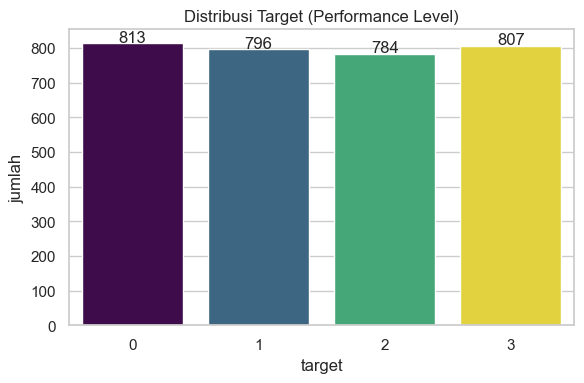

In [7]:

target_counts = train["target"].value_counts().sort_index()
print(target_counts)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="target", data=train, hue="target", palette="viridis", legend=False, ax=ax)
ax.set_title("Distribusi Target (Performance Level)")
ax.set_xlabel("target")
ax.set_ylabel("jumlah")
for i, v in enumerate(target_counts.values):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout()
plt.show()


### 1.4 Distribusi tiap fitur

Fitur dikelompokkan agar visualisasi tetap terbaca: grup `nilai_minggu_*`,
grup `aktivitas_hari_*`, dan grup fitur lainnya.

In [8]:

nilai_minggu_cols = [c for c in FEATURE_COLS if c.startswith("nilai_minggu_")]
aktivitas_cols = [c for c in FEATURE_COLS if c.startswith("aktivitas_hari_")]
other_cols = [c for c in FEATURE_COLS if c not in nilai_minggu_cols + aktivitas_cols]

print("nilai_minggu:", len(nilai_minggu_cols))
print("aktivitas_hari:", len(aktivitas_cols))
print("lainnya:", len(other_cols), "->", other_cols)


nilai_minggu: 12
aktivitas_hari: 16
lainnya: 13 -> ['skor_motivasi', 'skor_kedisiplinan', 'tugas_selesai', 'tugas_diberikan', 'kelas', 'urutan_ujian', 'skor_tryout', 'jarak_rumah_km', 'skor_ekstrakurikuler', 'indeks_kehadiran', 'skor_literasi', 'jumlah_saudara', 'skor_minat_belajar']


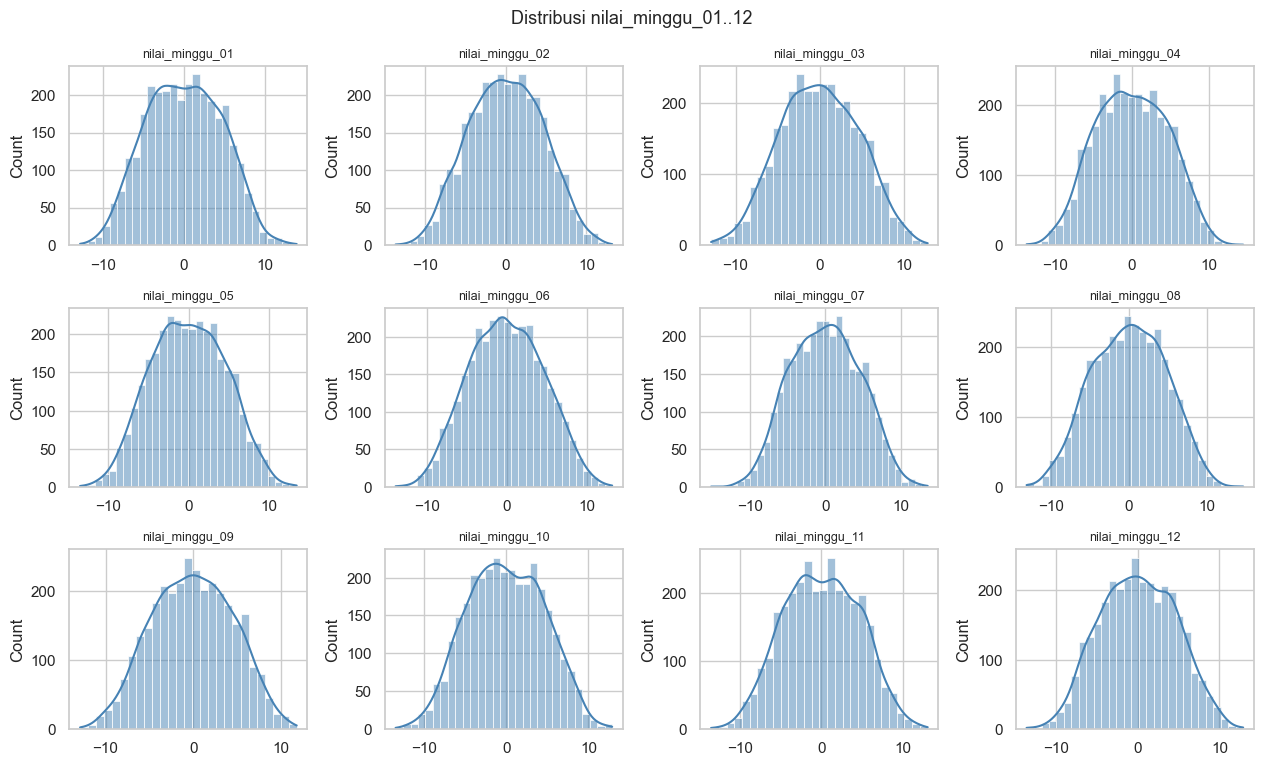

In [9]:

def plot_hist_grid(cols, ncols=4, title=""):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.2, nrows * 2.6))
    axes = np.array(axes).reshape(-1)
    for i, col in enumerate(cols):
        sns.histplot(train[col], kde=True, ax=axes[i], color="steelblue")
        axes[i].set_title(col, fontsize=9)
        axes[i].set_xlabel("")
    for j in range(len(cols), len(axes)):
        axes[j].axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

plot_hist_grid(nilai_minggu_cols, title="Distribusi nilai_minggu_01..12")


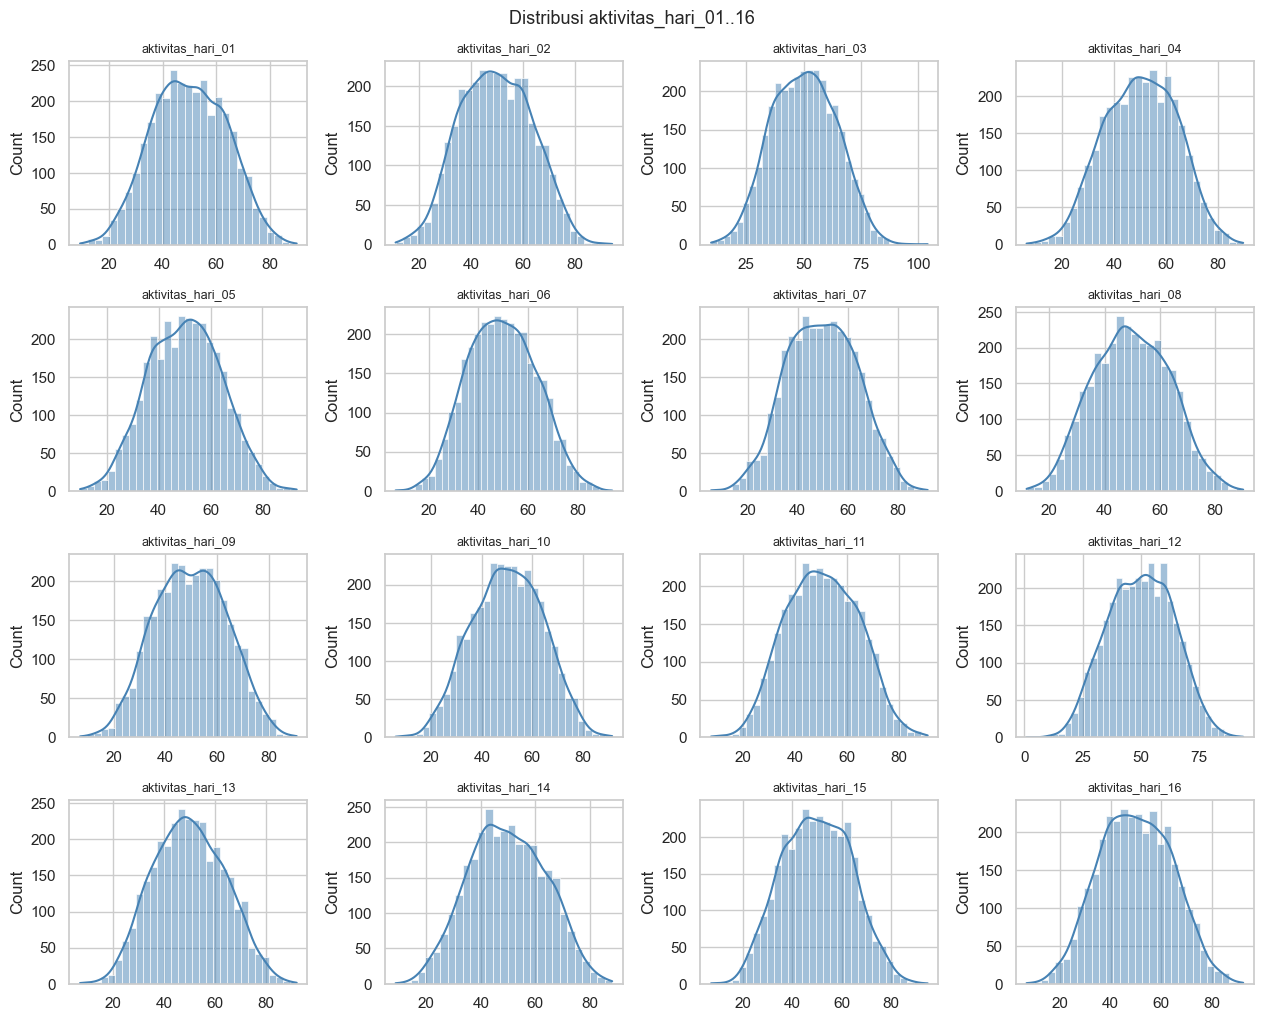

In [10]:

plot_hist_grid(aktivitas_cols, title="Distribusi aktivitas_hari_01..16")


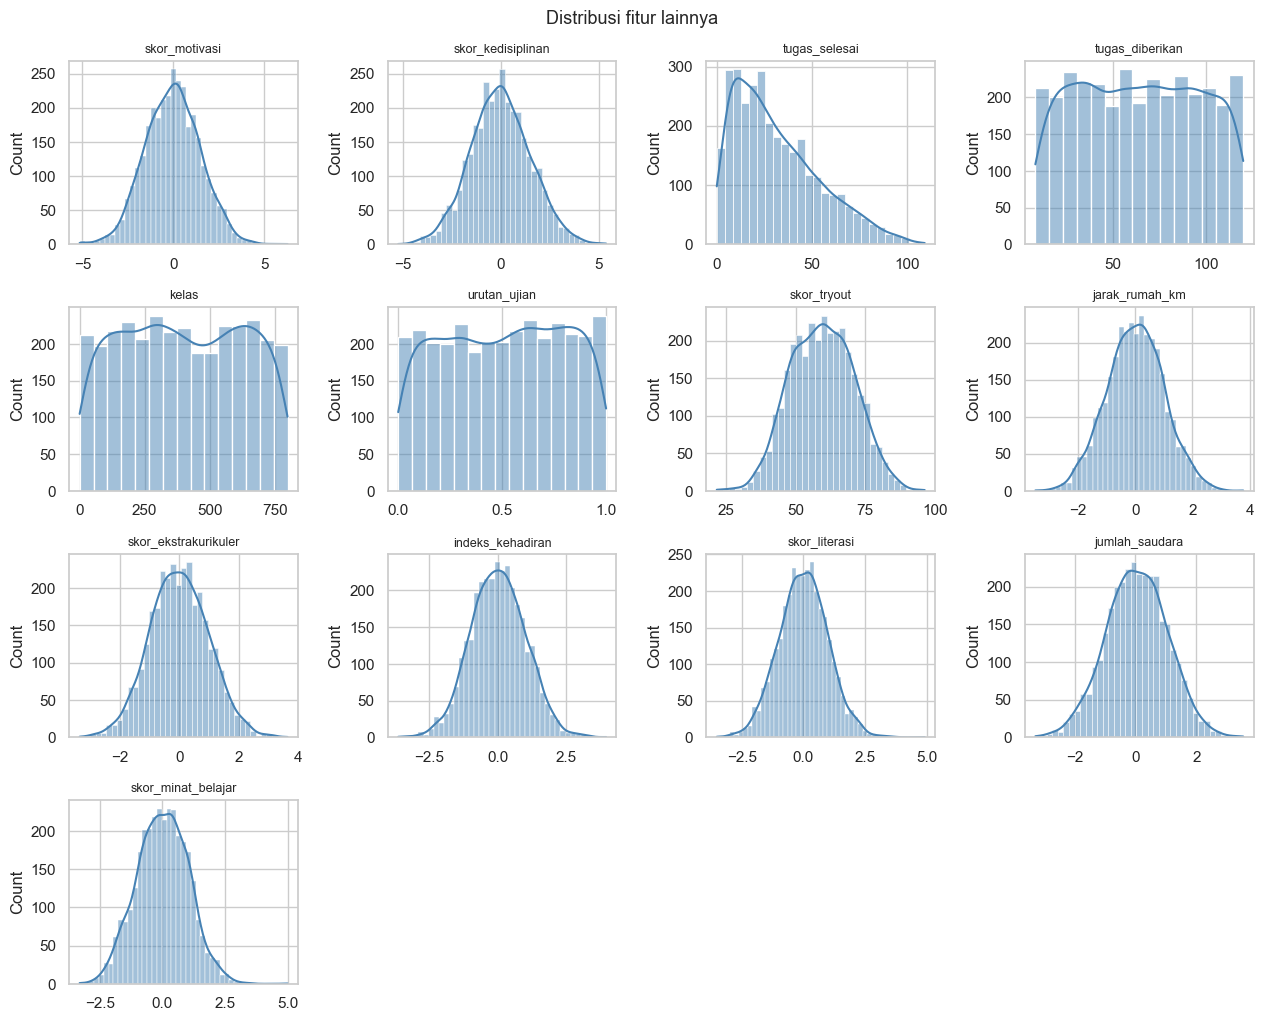

In [11]:

plot_hist_grid(other_cols, ncols=4, title="Distribusi fitur lainnya")


### 1.5 Boxplot per kelas target

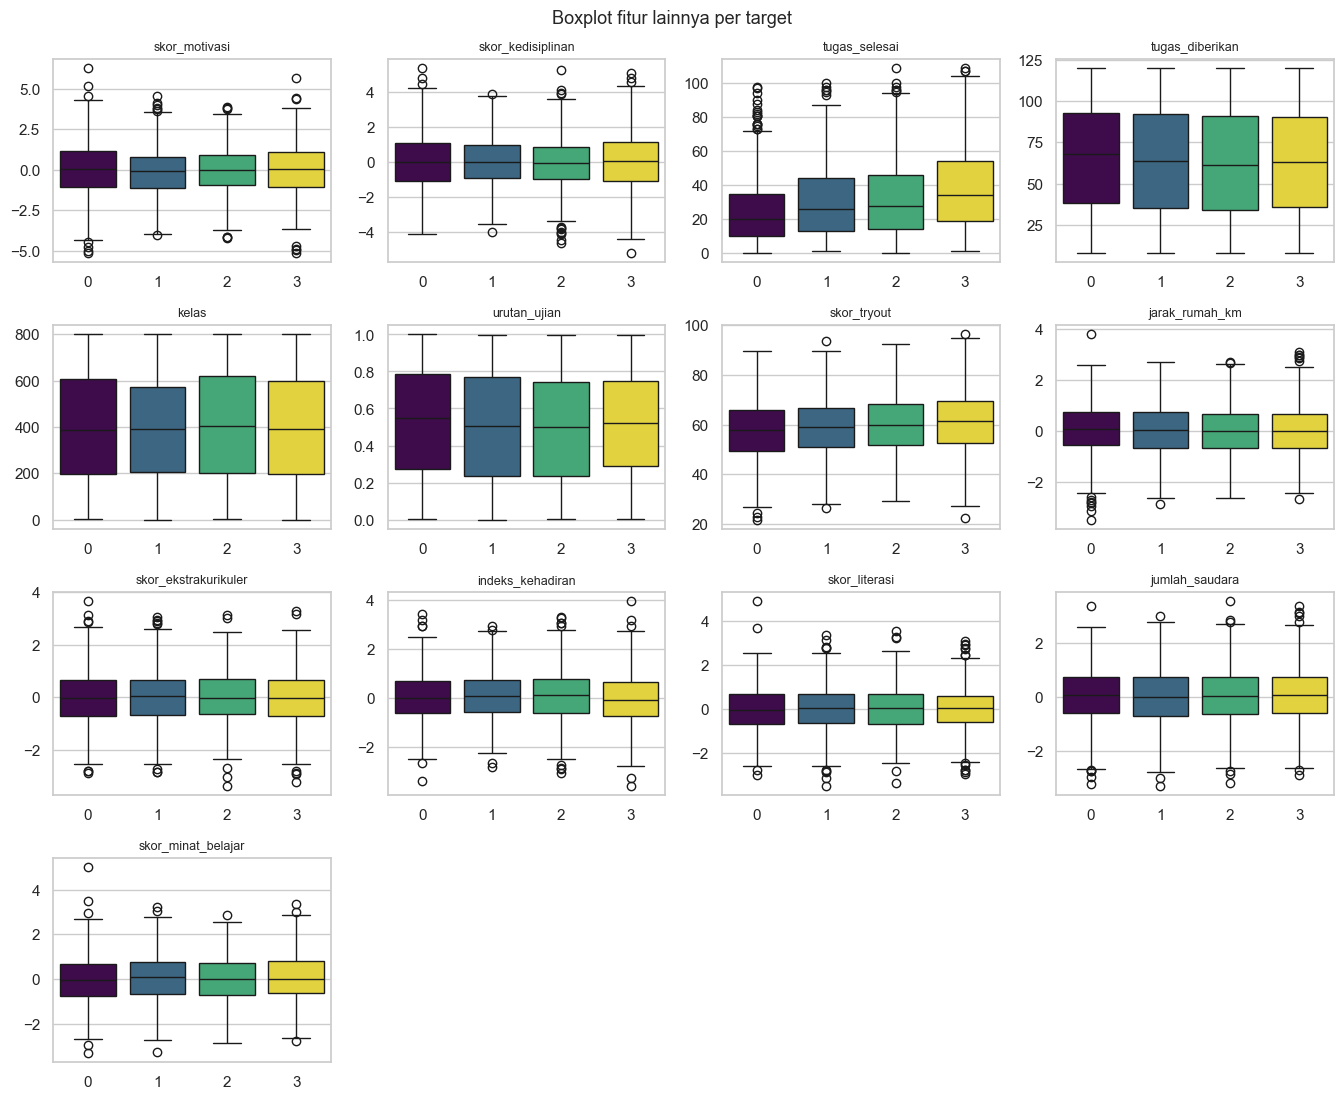

In [12]:

def plot_box_grid(cols, ncols=4, title=""):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.4, nrows * 2.8))
    axes = np.array(axes).reshape(-1)
    for i, col in enumerate(cols):
        sns.boxplot(x="target", y=col, data=train, hue="target", palette="viridis",
                    legend=False, ax=axes[i])
        axes[i].set_title(col, fontsize=9)
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")
    for j in range(len(cols), len(axes)):
        axes[j].axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

plot_box_grid(other_cols, title="Boxplot fitur lainnya per target")


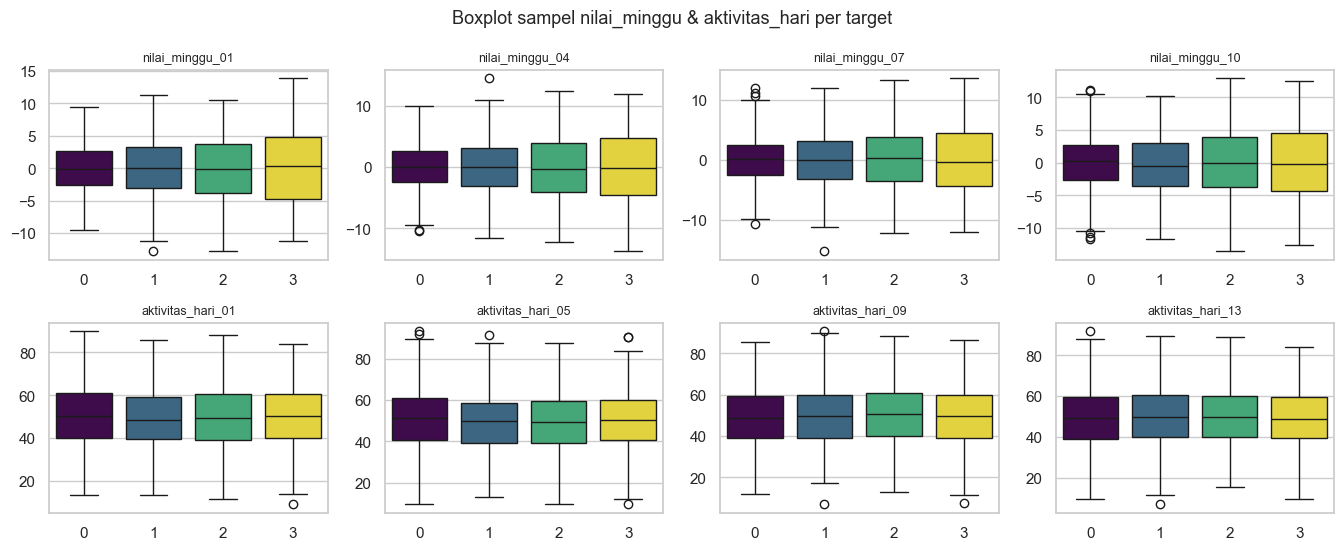

In [13]:

# Sample beberapa fitur nilai_minggu & aktivitas untuk boxplot (representatif)
sample_weekly = nilai_minggu_cols[::3]
sample_daily = aktivitas_cols[::4]
plot_box_grid(sample_weekly + sample_daily, title="Boxplot sampel nilai_minggu & aktivitas_hari per target")


### 1.6 Correlation heatmap

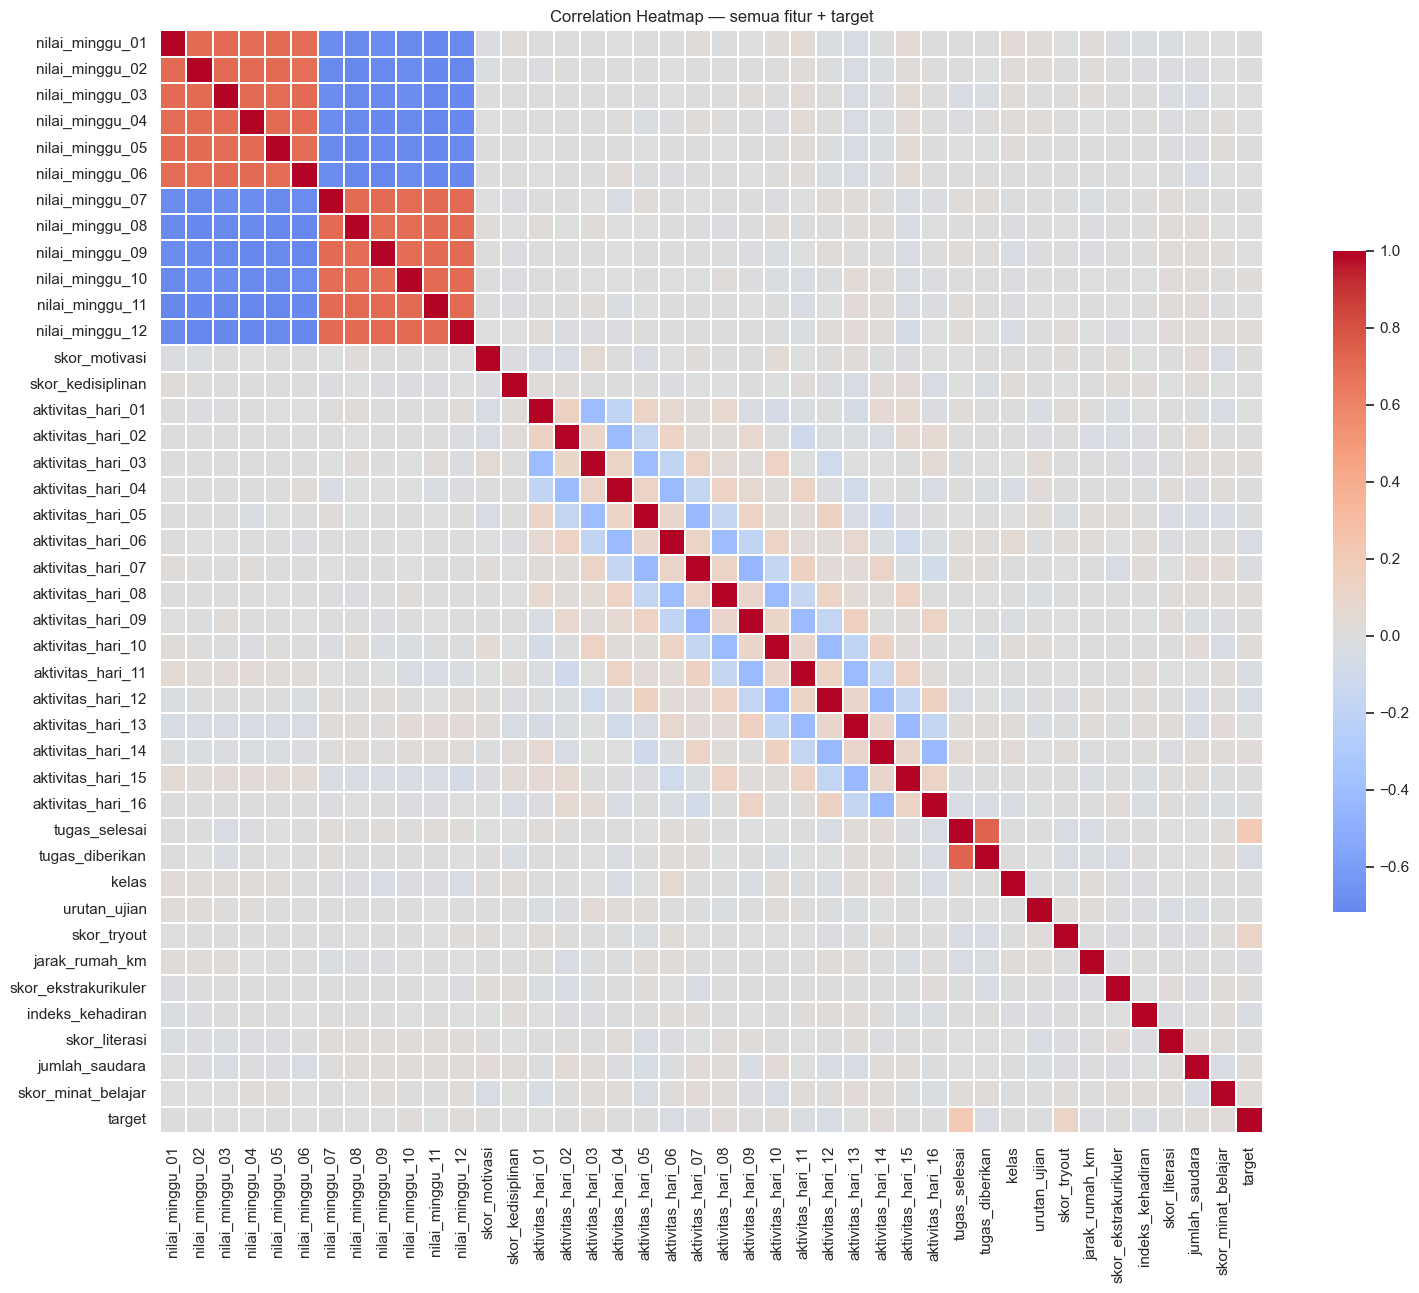

In [14]:

plt.figure(figsize=(16, 13))
corr = train[FEATURE_COLS + ["target"]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, linewidths=0.2, cbar_kws={"shrink": 0.6})
plt.title("Correlation Heatmap — semua fitur + target")
plt.tight_layout()
plt.show()


In [15]:

corr_with_target = corr["target"].drop("target").sort_values(key=np.abs, ascending=False)
print("Top 15 fitur dengan korelasi (absolut) tertinggi terhadap target:")
corr_with_target.head(15)


Top 15 fitur dengan korelasi (absolut) tertinggi terhadap target:


tugas_selesai         0.215018
skor_tryout           0.114157
aktivitas_hari_12    -0.044676
aktivitas_hari_14     0.032485
tugas_diberikan      -0.032351
aktivitas_hari_06    -0.031387
aktivitas_hari_08     0.027121
aktivitas_hari_11    -0.026962
skor_minat_belajar    0.026558
indeks_kehadiran     -0.022465
jarak_rumah_km       -0.019582
aktivitas_hari_07    -0.019421
aktivitas_hari_10     0.019200
aktivitas_hari_03     0.016612
jumlah_saudara        0.016003
Name: target, dtype: float64

### 1.7 Analisis khusus kolom `kelas`

Nama kolom `kelas` menyiratkan identitas kategori, tapi mari kita cek betulan seperti
apa: berapa banyak nilai unik, apakah polanya kontinu, dan bagaimana hubungannya
dengan target.

In [16]:

print("n_unique(kelas):", train["kelas"].nunique(), "dari", len(train), "baris")
print("range:", train["kelas"].min(), "-", train["kelas"].max())
print()
print(train["kelas"].describe())


n_unique(kelas): 786 dari 3200 baris
range: 0 - 799

count    3200.000000
mean      398.280000
std       229.802121
min         0.000000
25%       198.750000
50%       391.000000
75%       603.000000
max       799.000000
Name: kelas, dtype: float64


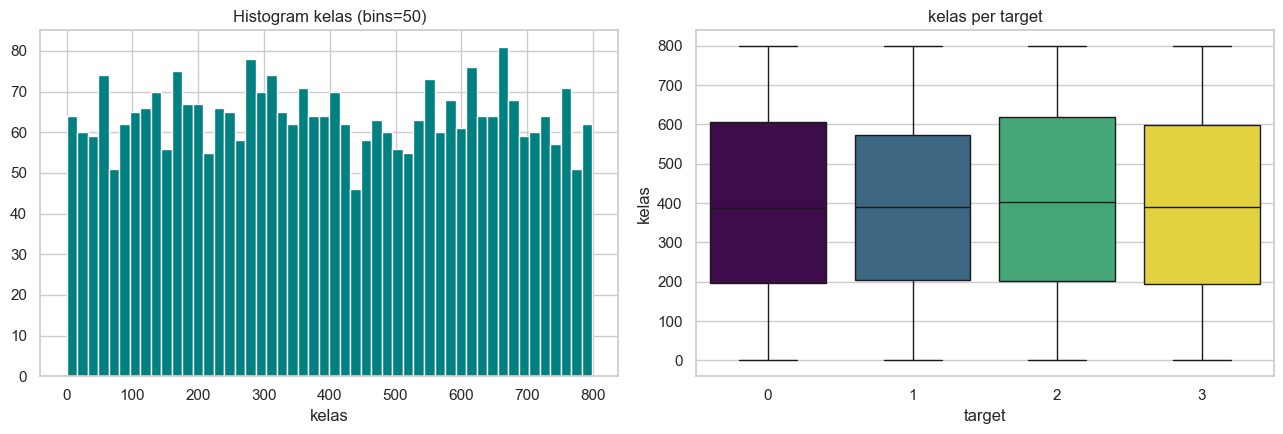

kelas punya 786 nilai unik dari 3200 baris (24.6% unik).
Rentang nilainya kontinu 0-799 dengan histogram yang mulus (bukan beberapa spike diskrit seperti label kategori/id kelas biasanya). Ini mengindikasikan 'kelas' sebenarnya adalah variabel numerik kontinu/ordinal (mis. semacam skor atau nomor urut), BUKAN categorical class identifier walau namanya begitu — sehingga kita perlakukan sebagai fitur numerik, tanpa one-hot encoding.


In [17]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(train["kelas"], bins=50, color="teal", edgecolor="white")
axes[0].set_title("Histogram kelas (bins=50)")
axes[0].set_xlabel("kelas")

sns.boxplot(x="target", y="kelas", data=train, hue="target", palette="viridis",
            legend=False, ax=axes[1])
axes[1].set_title("kelas per target")

plt.tight_layout()
plt.show()

print(
    f"kelas punya {train['kelas'].nunique()} nilai unik dari {len(train)} baris "
    f"({train['kelas'].nunique() / len(train) * 100:.1f}% unik).\n"
    "Rentang nilainya kontinu 0-799 dengan histogram yang mulus (bukan beberapa "
    "spike diskrit seperti label kategori/id kelas biasanya). Ini mengindikasikan "
    "'kelas' sebenarnya adalah variabel numerik kontinu/ordinal (mis. semacam skor "
    "atau nomor urut), BUKAN categorical class identifier walau namanya begitu — "
    "sehingga kita perlakukan sebagai fitur numerik, tanpa one-hot encoding."
)


### 1.8 Deteksi outlier (metode IQR)

In [18]:

def iqr_outlier_count(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

outlier_summary = pd.Series(
    {col: iqr_outlier_count(train[col]) for col in FEATURE_COLS}
).sort_values(ascending=False)

outlier_pct = (outlier_summary / len(train) * 100).round(2)
outlier_df = pd.DataFrame({"n_outlier": outlier_summary, "pct_outlier": outlier_pct})
outlier_df.head(15)


,n_outlier,pct_outlier
tugas_selesai,29,0.91
skor_literasi,28,0.88
skor_kedisiplinan,27,0.84
skor_ekstrakurikuler,25,0.78
indeks_kehadiran,22,0.69
skor_motivasi,22,0.69
jumlah_saudara,20,0.62
jarak_rumah_km,15,0.47
skor_minat_belajar,11,0.34
skor_tryout,7,0.22


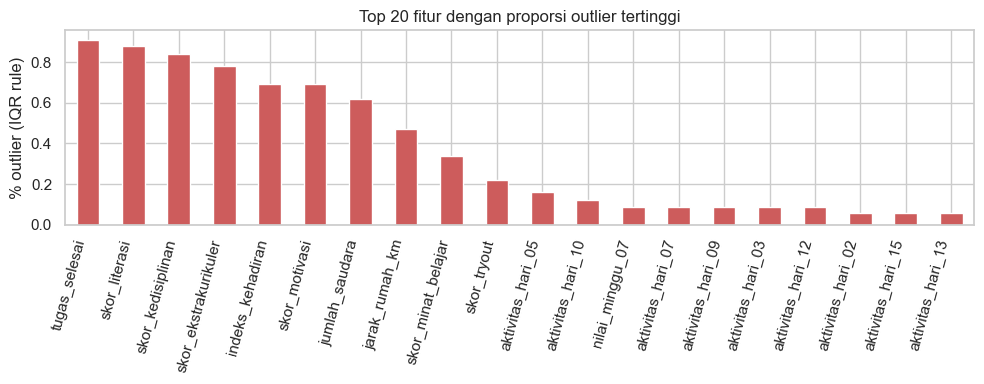

Total fitur dengan >1% outlier: 0 dari 41
Outlier akan dibiarkan apa adanya (bukan dihapus) karena model tree-based (LightGBM/XGBoost) & TabPFN cukup robust terhadap outlier, dan data kemungkinan sintetis sehingga 'outlier' bisa jadi bagian valid dari distribusi.


In [19]:

plt.figure(figsize=(10, 4))
outlier_df["pct_outlier"].sort_values(ascending=False).head(20).plot(kind="bar", color="indianred")
plt.ylabel("% outlier (IQR rule)")
plt.title("Top 20 fitur dengan proporsi outlier tertinggi")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

print(f"Total fitur dengan >1% outlier: {(outlier_df['pct_outlier'] > 1).sum()} dari {len(FEATURE_COLS)}")
print("Outlier akan dibiarkan apa adanya (bukan dihapus) karena model tree-based "
      "(LightGBM/XGBoost) & TabPFN cukup robust terhadap outlier, dan data "
      "kemungkinan sintetis sehingga 'outlier' bisa jadi bagian valid dari distribusi.")


## 2. Feature Engineering

### 2.1 Fitur agregat dari `nilai_minggu_01..12`

Untuk setiap baris, hitung `mean`, `std`, `min`, `max`, dan `slope` (tren naik/turun
lewat regresi linear sederhana terhadap urutan minggu 1..12).

In [20]:

def add_slope(df, cols, out_name):
    """Slope regresi linear per baris terhadap urutan indeks kolom (0..n-1)."""
    X = np.arange(len(cols))
    X_mean = X.mean()
    X_var = ((X - X_mean) ** 2).sum()
    vals = df[cols].to_numpy()
    y_mean = vals.mean(axis=1, keepdims=True)
    slope = ((vals - y_mean) * (X - X_mean)).sum(axis=1) / X_var
    df[out_name] = slope
    return df


def add_aggregates(df, cols, prefix):
    df[f"{prefix}_mean"] = df[cols].mean(axis=1)
    df[f"{prefix}_std"] = df[cols].std(axis=1)
    df[f"{prefix}_min"] = df[cols].min(axis=1)
    df[f"{prefix}_max"] = df[cols].max(axis=1)
    df = add_slope(df, cols, f"{prefix}_slope")
    return df


def engineer_features(df):
    df = df.copy()
    df = add_aggregates(df, nilai_minggu_cols, "nilai_minggu")
    df = add_aggregates(df, aktivitas_cols, "aktivitas")

    # Completion rate tugas (hindari div-by-zero)
    df["completion_rate"] = df["tugas_selesai"] / df["tugas_diberikan"].replace(0, np.nan)
    df["completion_rate"] = df["completion_rate"].fillna(0)

    # Interaksi relevan
    df["tryout_per_urutan"] = df["skor_tryout"] / (df["urutan_ujian"] + 1)
    df["motivasi_x_disiplin"] = df["skor_motivasi"] * df["skor_kedisiplinan"]

    return df


train_eng = engineer_features(train)
test_eng = engineer_features(test)

ENGINEERED_COLS = [c for c in train_eng.columns if c not in list(train.columns) + ["target"]]
print(f"Jumlah fitur baru: {len(ENGINEERED_COLS)}")
print(ENGINEERED_COLS)
train_eng[ENGINEERED_COLS].describe().T


Jumlah fitur baru: 13
['nilai_minggu_mean', 'nilai_minggu_std', 'nilai_minggu_min', 'nilai_minggu_max', 'nilai_minggu_slope', 'aktivitas_mean', 'aktivitas_std', 'aktivitas_min', 'aktivitas_max', 'aktivitas_slope', 'completion_rate', 'tryout_per_urutan', 'motivasi_x_disiplin']


,count,mean,std,min,25%,50%,75%,max
nilai_minggu_mean,3200.0,0.004828,0.707452,-2.925000,-0.468750,-0.008333,0.466667,2.341667
nilai_minggu_std,3200.0,4.438297,1.679678,1.070648,3.042763,4.206358,5.713038,9.249652
nilai_minggu_min,3200.0,-6.592875,2.392362,-15.200000,-8.300000,-6.500000,-4.800000,-0.400000
nilai_minggu_max,3200.0,6.633281,2.385541,0.100000,4.800000,6.500000,8.300000,14.700000
nilai_minggu_slope,3200.0,0.001012,0.993489,-2.176573,-0.830769,-0.011713,0.848252,2.272727
aktivitas_mean,3200.0,49.930217,2.393653,41.243750,48.243750,49.862500,51.625000,57.681250
aktivitas_std,3200.0,13.943677,2.093703,6.889312,12.523381,13.902151,15.365333,22.077325
aktivitas_min,3200.0,26.190875,5.815249,0.900000,22.500000,26.600000,30.300000,42.300000
aktivitas_max,3200.0,74.077812,5.872972,54.900000,70.000000,73.800000,77.800000,104.000000
aktivitas_slope,3200.0,0.000235,0.566221,-2.252794,-0.390735,-0.005294,0.381581,1.891324


### 2.2 Eksplorasi interaksi antar fitur

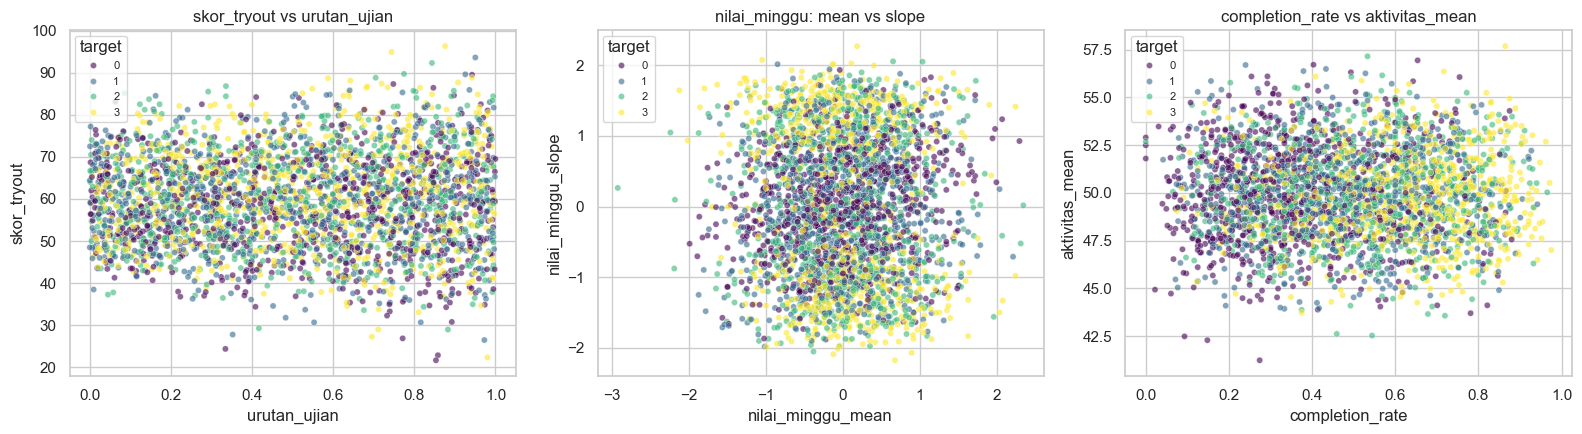

In [21]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.scatterplot(data=train_eng, x="urutan_ujian", y="skor_tryout", hue="target",
                 palette="viridis", alpha=0.6, s=20, ax=axes[0])
axes[0].set_title("skor_tryout vs urutan_ujian")

sns.scatterplot(data=train_eng, x="nilai_minggu_mean", y="nilai_minggu_slope", hue="target",
                 palette="viridis", alpha=0.6, s=20, ax=axes[1])
axes[1].set_title("nilai_minggu: mean vs slope")

sns.scatterplot(data=train_eng, x="completion_rate", y="aktivitas_mean", hue="target",
                 palette="viridis", alpha=0.6, s=20, ax=axes[2])
axes[2].set_title("completion_rate vs aktivitas_mean")

for ax in axes:
    ax.legend(title="target", fontsize=8)
plt.tight_layout()
plt.show()


In [22]:

eng_corr = train_eng[ENGINEERED_COLS + ["target"]].corr()["target"].drop("target").sort_values(key=np.abs, ascending=False)
print("Korelasi fitur engineered terhadap target:")
eng_corr


Korelasi fitur engineered terhadap target:


completion_rate        0.404539
nilai_minggu_std       0.395633
motivasi_x_disiplin    0.382429
nilai_minggu_max       0.338395
nilai_minggu_min      -0.325331
tryout_per_urutan      0.075214
aktivitas_max         -0.044249
aktivitas_std         -0.039319
aktivitas_min          0.026977
nilai_minggu_mean      0.013472
aktivitas_mean        -0.012912
aktivitas_slope       -0.004911
nilai_minggu_slope     0.000706
Name: target, dtype: float64

### 2.3 Simpan dua versi dataset

In [23]:

# (a) fitur asli saja
X_original = train[FEATURE_COLS].copy()
X_test_original = test[FEATURE_COLS].copy()

# (b) fitur asli + engineered
X_engineered = train_eng[FEATURE_COLS + ENGINEERED_COLS].copy()
X_test_engineered = test_eng[FEATURE_COLS + ENGINEERED_COLS].copy()

y = train["target"].copy()
test_ids = test["id"].copy()

print("X_original :", X_original.shape)
print("X_engineered:", X_engineered.shape)


X_original : (3200, 41)
X_engineered: (3200, 54)


## 3. Preprocessing

### 3.1 Stratified split & Stratified K-Fold

Karena ini multi-kelas dengan target balanced, kita pakai `StratifiedKFold` 5-fold
untuk cross-validation yang robust di semua tahap modeling & evaluasi.

In [24]:

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# fold index disimpan supaya konsisten dipakai ulang oleh semua model
fold_indices = list(skf.split(X_engineered, y))
for i, (tr_idx, va_idx) in enumerate(fold_indices):
    print(f"fold {i}: train={len(tr_idx)}, val={len(va_idx)}, "
          f"val class balance={np.bincount(y.iloc[va_idx])}")


fold 0: train=2560, val=640, val class balance=[163 159 156 162]
fold 1: train=2560, val=640, val class balance=[162 159 157 162]
fold 2: train=2560, val=640, val class balance=[162 160 157 161]
fold 3: train=2560, val=640, val class balance=[163 159 157 161]
fold 4: train=2560, val=640, val class balance=[163 159 157 161]


### 3.2 Scaling

Model tree-based (LightGBM/XGBoost) tidak butuh scaling, tapi TabPFN & perbandingan
jarak/interaksi lebih stabil dengan fitur yang distandardisasi. Kita siapkan versi
scaled yang di-fit hanya di data train tiap fold (dipakai di bagian TabPFN) supaya
tidak ada data leakage, dan versi scaled penuh untuk transform ke test set.

In [25]:

def make_scaled(X_train_fold, X_other):
    """Fit StandardScaler di X_train_fold, transform X_other. Return both as DataFrame."""
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train_fold), columns=X_train_fold.columns, index=X_train_fold.index
    )
    X_other_scaled = pd.DataFrame(
        scaler.transform(X_other), columns=X_other.columns, index=X_other.index
    )
    return X_train_scaled, X_other_scaled, scaler

print("Helper scaling siap. Scaler akan di-fit ulang per fold di dalam loop CV "
      "(bagian modeling) agar tidak ada leakage antar fold, lalu di-fit sekali lagi "
      "pada seluruh train untuk transform ke test set final.")


Helper scaling siap. Scaler akan di-fit ulang per fold di dalam loop CV (bagian modeling) agar tidak ada leakage antar fold, lalu di-fit sekali lagi pada seluruh train untuk transform ke test set final.


## 4. Modeling

Kita bandingkan 3 pendekatan, semuanya dievaluasi dengan 5-fold CV yang sama
(`fold_indices`) di atas dataset **(b) fitur asli + engineered**, supaya perbandingan
antar model adil. Skor per model juga akan dibandingkan dataset (a) vs (b) di bagian
evaluasi untuk melihat efek feature engineering.

Metrik CV per fold disimpan di `cv_results` (dict of list) untuk dipakai di bagian 5.

In [26]:

cv_results = {}   # model_name -> {"accuracy": [...], "f1_macro": [...], "logloss": [...]}
oof_proba = {}    # model_name -> np.array shape (n_train, N_CLASSES), out-of-fold probabilities

def evaluate_fold(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "logloss": log_loss(y_true, y_proba, labels=list(range(N_CLASSES))),
    }

def summarize_cv(name):
    res = cv_results[name]
    print(f"--- {name} ---")
    for metric in ["accuracy", "f1_macro", "logloss"]:
        vals = np.array(res[metric])
        print(f"  {metric:10s}: {vals.mean():.4f} +/- {vals.std():.4f}")


### 4.a Gradient Boosting — LightGBM vs XGBoost

Hyperparameter tuning ringan dengan Optuna (search space kecil, jumlah trial
terbatas) dievaluasi lewat rata-rata log-loss 5-fold CV.

In [27]:

import lightgbm as lgb
import xgboost as xgb
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

X = X_engineered.reset_index(drop=True)
y_arr = y.reset_index(drop=True)


def cv_logloss_lgb(params, X, y, fold_indices):
    losses = []
    for tr_idx, va_idx in fold_indices:
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
        model = lgb.LGBMClassifier(
            objective="multiclass", num_class=N_CLASSES, random_state=RANDOM_STATE,
            verbosity=-1, **params,
        )
        model.fit(X_tr, y_tr)
        proba = model.predict_proba(X_va)
        losses.append(log_loss(y_va, proba, labels=list(range(N_CLASSES))))
    return np.mean(losses)


def objective_lgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 63),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 5.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 5.0, log=True),
    }
    return cv_logloss_lgb(params, X, y_arr, fold_indices)


study_lgb = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_lgb.optimize(objective_lgb, n_trials=25, show_progress_bar=False)

print("Best LightGBM logloss (CV):", study_lgb.best_value)
print("Best params:", study_lgb.best_params)


Best LightGBM logloss (CV): 1.0527077488945462
Best params: {'n_estimators': 306, 'learning_rate': 0.05898602410432694, 'num_leaves': 9, 'max_depth': 7, 'min_child_samples': 12, 'subsample': 0.6260206371941118, 'colsample_bytree': 0.9795542149013333, 'reg_alpha': 3.7311604524743114, 'reg_lambda': 0.9777718780862645}


In [28]:

def cv_logloss_xgb(params, X, y, fold_indices):
    losses = []
    for tr_idx, va_idx in fold_indices:
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
        model = xgb.XGBClassifier(
            objective="multi:softprob", num_class=N_CLASSES, random_state=RANDOM_STATE,
            eval_metric="mlogloss", tree_method="hist", verbosity=0, **params,
        )
        model.fit(X_tr, y_tr)
        proba = model.predict_proba(X_va)
        losses.append(log_loss(y_va, proba, labels=list(range(N_CLASSES))))
    return np.mean(losses)


def objective_xgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 5.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 5.0, log=True),
    }
    return cv_logloss_xgb(params, X, y_arr, fold_indices)


study_xgb = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_xgb.optimize(objective_xgb, n_trials=25, show_progress_bar=False)

print("Best XGBoost logloss (CV):", study_xgb.best_value)
print("Best params:", study_xgb.best_params)


Best XGBoost logloss (CV): 1.0475597850199851
Best params: {'n_estimators': 448, 'learning_rate': 0.03479307712569651, 'max_depth': 5, 'min_child_weight': 5, 'subsample': 0.6055457099618505, 'colsample_bytree': 0.8102803826231137, 'reg_alpha': 0.03926444810606471, 'reg_lambda': 0.0010020295263250983}


In [29]:

best_lgb_params = study_lgb.best_params
best_xgb_params = study_xgb.best_params

def run_cv_model(name, fit_predict_fn, X, y, fold_indices):
    oof = np.zeros((len(X), N_CLASSES))
    metrics = {"accuracy": [], "f1_macro": [], "logloss": []}
    for tr_idx, va_idx in fold_indices:
        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
        proba = fit_predict_fn(X_tr, y_tr, X_va)
        oof[va_idx] = proba
        pred = np.argmax(proba, axis=1)
        m = evaluate_fold(y_va, pred, proba)
        for k in metrics:
            metrics[k].append(m[k])
    cv_results[name] = metrics
    oof_proba[name] = oof
    return oof


def lgb_fit_predict(X_tr, y_tr, X_va):
    model = lgb.LGBMClassifier(objective="multiclass", num_class=N_CLASSES,
                                random_state=RANDOM_STATE, verbosity=-1, **best_lgb_params)
    model.fit(X_tr, y_tr)
    return model.predict_proba(X_va)


def xgb_fit_predict(X_tr, y_tr, X_va):
    model = xgb.XGBClassifier(objective="multi:softprob", num_class=N_CLASSES,
                               random_state=RANDOM_STATE, eval_metric="mlogloss",
                               tree_method="hist", verbosity=0, **best_xgb_params)
    model.fit(X_tr, y_tr)
    return model.predict_proba(X_va)


run_cv_model("LightGBM", lgb_fit_predict, X, y_arr, fold_indices)
run_cv_model("XGBoost", xgb_fit_predict, X, y_arr, fold_indices)

summarize_cv("LightGBM")
summarize_cv("XGBoost")


--- LightGBM ---
  accuracy  : 0.5075 +/- 0.0176
  f1_macro  : 0.4965 +/- 0.0167
  logloss   : 1.0527 +/- 0.0282
--- XGBoost ---
  accuracy  : 0.5166 +/- 0.0153
  f1_macro  : 0.5054 +/- 0.0127
  logloss   : 1.0476 +/- 0.0275


### 4.b TabPFN

Dataset ini kecil (3200 baris train, 54 fitur setelah engineering, 4 kelas) sehingga
masuk batas resmi TabPFN. Fitur di-scale per fold untuk stabilitas numerik.

In [30]:

from tabpfn import TabPFNClassifier
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print("TabPFN device:", device)

def tabpfn_fit_predict(X_tr, y_tr, X_va):
    X_tr_s, X_va_s, _ = make_scaled(X_tr, X_va)
    model = TabPFNClassifier(random_state=RANDOM_STATE, device=device)
    model.fit(X_tr_s.to_numpy(), y_tr.to_numpy())
    return model.predict_proba(X_va_s.to_numpy())


run_cv_model("TabPFN", tabpfn_fit_predict, X, y_arr, fold_indices)
summarize_cv("TabPFN")


TabPFN device: cuda


--- TabPFN ---
  accuracy  : 0.5650 +/- 0.0266
  f1_macro  : 0.5578 +/- 0.0256
  logloss   : 0.9563 +/- 0.0267


### 4.c Ensemble — blend GBDT terbaik + TabPFN

Pilih GBDT dengan logloss CV terbaik lalu blend `predict_proba`-nya (rata-rata
sederhana) dengan TabPFN, dievaluasi di fold yang sama menggunakan OOF predictions
yang sudah dihitung di atas (tidak perlu re-fit).

In [31]:

best_gbdt_name = "LightGBM" if np.mean(cv_results["LightGBM"]["logloss"]) <= np.mean(cv_results["XGBoost"]["logloss"]) else "XGBoost"
print("GBDT terbaik:", best_gbdt_name)

ensemble_oof = 0.5 * oof_proba[best_gbdt_name] + 0.5 * oof_proba["TabPFN"]

metrics = {"accuracy": [], "f1_macro": [], "logloss": []}
for tr_idx, va_idx in fold_indices:
    y_va = y_arr.iloc[va_idx]
    proba = ensemble_oof[va_idx]
    pred = np.argmax(proba, axis=1)
    m = evaluate_fold(y_va, pred, proba)
    for k in metrics:
        metrics[k].append(m[k])

cv_results["Ensemble"] = metrics
oof_proba["Ensemble"] = ensemble_oof
summarize_cv("Ensemble")


GBDT terbaik: XGBoost
--- Ensemble ---
  accuracy  : 0.5516 +/- 0.0154
  f1_macro  : 0.5398 +/- 0.0140
  logloss   : 0.9776 +/- 0.0261


## 5. Evaluasi

### 5.1 Tabel perbandingan CV (mean +/- std)

In [32]:

summary_rows = []
for name, metrics in cv_results.items():
    row = {"model": name}
    for metric in ["accuracy", "f1_macro", "logloss"]:
        vals = np.array(metrics[metric])
        row[f"{metric}_mean"] = vals.mean()
        row[f"{metric}_std"] = vals.std()
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("model")
summary_df = summary_df.sort_values("f1_macro_mean", ascending=False)
summary_df.style.format("{:.4f}")


,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,logloss_mean,logloss_std
model,,,,,,
TabPFN,0.5650,0.0266,0.5578,0.0256,0.9563,0.0267
Ensemble,0.5516,0.0154,0.5398,0.0140,0.9776,0.0261
XGBoost,0.5166,0.0153,0.5054,0.0127,1.0476,0.0275
LightGBM,0.5075,0.0176,0.4965,0.0167,1.0527,0.0282


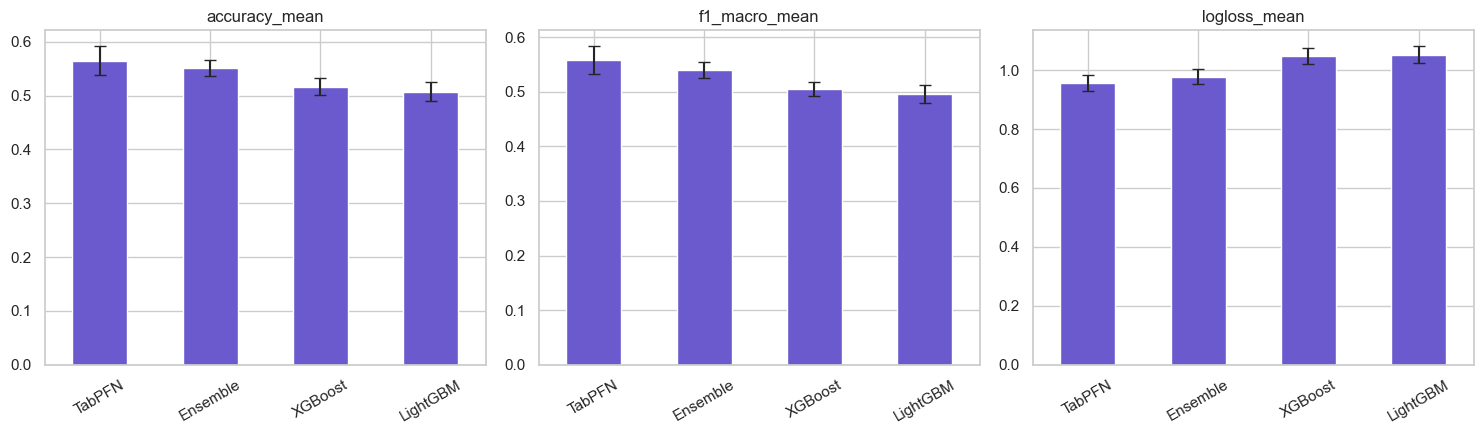

In [33]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric in zip(axes, ["accuracy_mean", "f1_macro_mean", "logloss_mean"]):
    std_col = metric.replace("_mean", "_std")
    summary_df[metric].plot(kind="bar", yerr=summary_df[std_col], ax=ax,
                             color="slateblue", capsize=4)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


### 5.2 Confusion matrix — model terbaik

Model terbaik (berdasarkan macro F1 CV): TabPFN


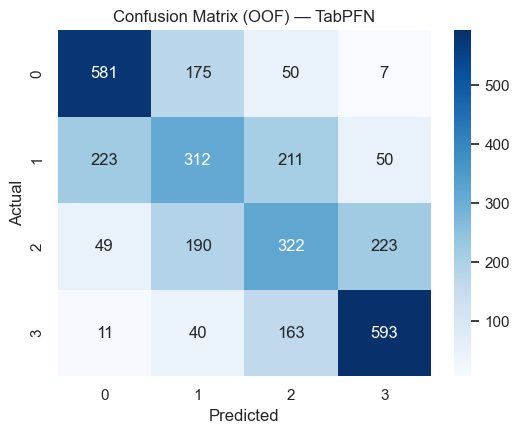

              precision    recall  f1-score   support

           0     0.6725    0.7146    0.6929       813
           1     0.4351    0.3920    0.4124       796
           2     0.4316    0.4107    0.4209       784
           3     0.6793    0.7348    0.7060       807

    accuracy                         0.5650      3200
   macro avg     0.5546    0.5630    0.5580      3200
weighted avg     0.5561    0.5650    0.5598      3200



In [34]:

best_model_name = summary_df["f1_macro_mean"].idxmax()
print("Model terbaik (berdasarkan macro F1 CV):", best_model_name)

best_oof_proba = oof_proba[best_model_name]
best_oof_pred = np.argmax(best_oof_proba, axis=1)

cm = confusion_matrix(y_arr, best_oof_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=range(N_CLASSES), yticklabels=range(N_CLASSES))
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix (OOF) — {best_model_name}")
plt.tight_layout()
plt.show()

print(classification_report(y_arr, best_oof_pred, digits=4))


### 5.3 Feature importance (GBDT) & efek feature engineering

Latih ulang model GBDT terbaik pada seluruh data train untuk melihat feature
importance, lalu cek proporsi fitur hasil engineering di top-N.

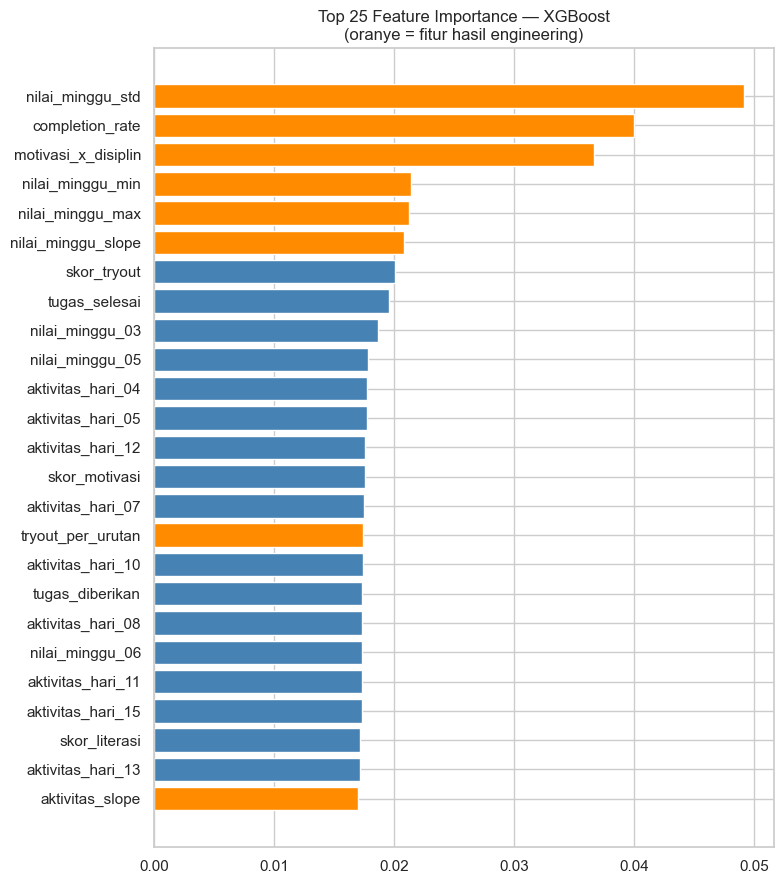

Fitur engineered di top-25 importance: 8 / 25


,feature,importance,is_engineered
42,nilai_minggu_std,0.049226,True
51,completion_rate,0.040042,True
53,motivasi_x_disiplin,0.036650,True
43,nilai_minggu_min,0.021447,True
44,nilai_minggu_max,0.021231,True
45,nilai_minggu_slope,0.020865,True
34,skor_tryout,0.020075,False
30,tugas_selesai,0.019565,False
2,nilai_minggu_03,0.018704,False
4,nilai_minggu_05,0.017865,False


In [35]:

if best_gbdt_name == "LightGBM":
    final_gbdt = lgb.LGBMClassifier(objective="multiclass", num_class=N_CLASSES,
                                     random_state=RANDOM_STATE, verbosity=-1, **best_lgb_params)
else:
    final_gbdt = xgb.XGBClassifier(objective="multi:softprob", num_class=N_CLASSES,
                                    random_state=RANDOM_STATE, eval_metric="mlogloss",
                                    tree_method="hist", verbosity=0, **best_xgb_params)

final_gbdt.fit(X, y_arr)

importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": final_gbdt.feature_importances_,
    "is_engineered": [c in ENGINEERED_COLS for c in X.columns],
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 9))
top_n = importance_df.head(25)
colors = top_n["is_engineered"].map({True: "darkorange", False: "steelblue"})
plt.barh(top_n["feature"][::-1], top_n["importance"][::-1], color=colors[::-1])
plt.title(f"Top 25 Feature Importance — {best_gbdt_name}\n(oranye = fitur hasil engineering)")
plt.tight_layout()
plt.show()

n_eng_in_top25 = importance_df.head(25)["is_engineered"].sum()
print(f"Fitur engineered di top-25 importance: {n_eng_in_top25} / 25")
importance_df.head(15)


### 5.4 Efek feature engineering — dataset (a) original vs (b) engineered

Latih model GBDT terbaik (parameter sama) pada kedua versi dataset untuk melihat
apakah fitur hasil engineering benar-benar menambah performa.

In [36]:

def cv_score_dataset(X_data, y, fold_indices, params, model_type):
    metrics = {"accuracy": [], "f1_macro": [], "logloss": []}
    for tr_idx, va_idx in fold_indices:
        X_tr, X_va = X_data.iloc[tr_idx], X_data.iloc[va_idx]
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
        if model_type == "LightGBM":
            model = lgb.LGBMClassifier(objective="multiclass", num_class=N_CLASSES,
                                        random_state=RANDOM_STATE, verbosity=-1, **params)
        else:
            model = xgb.XGBClassifier(objective="multi:softprob", num_class=N_CLASSES,
                                       random_state=RANDOM_STATE, eval_metric="mlogloss",
                                       tree_method="hist", verbosity=0, **params)
        model.fit(X_tr, y_tr)
        proba = model.predict_proba(X_va)
        pred = np.argmax(proba, axis=1)
        m = evaluate_fold(y_va, pred, proba)
        for k in metrics:
            metrics[k].append(m[k])
    return {k: (np.mean(v), np.std(v)) for k, v in metrics.items()}


params_for_compare = best_lgb_params if best_gbdt_name == "LightGBM" else best_xgb_params

score_original = cv_score_dataset(X_original.reset_index(drop=True), y_arr, fold_indices, params_for_compare, best_gbdt_name)
score_engineered = cv_score_dataset(X, y_arr, fold_indices, params_for_compare, best_gbdt_name)

compare_df = pd.DataFrame({
    "original_only": {k: f"{v[0]:.4f} +/- {v[1]:.4f}" for k, v in score_original.items()},
    "original_plus_engineered": {k: f"{v[0]:.4f} +/- {v[1]:.4f}" for k, v in score_engineered.items()},
}).T
compare_df


,accuracy,f1_macro,logloss
original_only,0.4669 +/- 0.0246,0.4570 +/- 0.0249,1.1506 +/- 0.0291
original_plus_engineered,0.5166 +/- 0.0153,0.5054 +/- 0.0127,1.0476 +/- 0.0275


### 5.5 Tabel ringkasan akhir

In [37]:

print("=== Ringkasan perbandingan model (5-fold CV, dataset original+engineered) ===")
summary_df.style.format("{:.4f}").background_gradient(subset=["f1_macro_mean"], cmap="Greens")


=== Ringkasan perbandingan model (5-fold CV, dataset original+engineered) ===


,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,logloss_mean,logloss_std
model,,,,,,
TabPFN,0.5650,0.0266,0.5578,0.0256,0.9563,0.0267
Ensemble,0.5516,0.0154,0.5398,0.0140,0.9776,0.0261
XGBoost,0.5166,0.0153,0.5054,0.0127,1.0476,0.0275
LightGBM,0.5075,0.0176,0.4965,0.0167,1.0527,0.0282


## 6. Submission

Latih ulang model/ensemble terbaik pada **seluruh** data train, lalu prediksi
`test.csv`. Model final ditentukan otomatis dari `best_model_name` di bagian
evaluasi (bisa GBDT tunggal, TabPFN, atau ensemble).

In [38]:

X_test = X_test_engineered.reset_index(drop=True)

def predict_full_lgb():
    model = lgb.LGBMClassifier(objective="multiclass", num_class=N_CLASSES,
                                random_state=RANDOM_STATE, verbosity=-1, **best_lgb_params)
    model.fit(X, y_arr)
    return model.predict_proba(X_test)

def predict_full_xgb():
    model = xgb.XGBClassifier(objective="multi:softprob", num_class=N_CLASSES,
                               random_state=RANDOM_STATE, eval_metric="mlogloss",
                               tree_method="hist", verbosity=0, **best_xgb_params)
    model.fit(X, y_arr)
    return model.predict_proba(X_test)

def predict_full_tabpfn():
    X_tr_s, X_te_s, _ = make_scaled(X, X_test)
    model = TabPFNClassifier(random_state=RANDOM_STATE, device=device)
    model.fit(X_tr_s.to_numpy(), y_arr.to_numpy())
    return model.predict_proba(X_te_s.to_numpy())


gbdt_test_proba = predict_full_lgb() if best_gbdt_name == "LightGBM" else predict_full_xgb()

if best_model_name == "TabPFN":
    test_proba = predict_full_tabpfn()
elif best_model_name == "Ensemble":
    tabpfn_test_proba = predict_full_tabpfn()
    test_proba = 0.5 * gbdt_test_proba + 0.5 * tabpfn_test_proba
else:
    test_proba = gbdt_test_proba

test_pred = np.argmax(test_proba, axis=1)
print("Model final dipakai untuk submission:", best_model_name)
print("Distribusi prediksi test:", np.bincount(test_pred))


Model final dipakai untuk submission: TabPFN
Distribusi prediksi test: [198 186 204 212]


In [39]:

submission = pd.DataFrame({"id": test_ids, "target": test_pred})

assert list(submission.columns) == list(sample_sub.columns), "Kolom submission harus sama dengan sample_submission"
assert len(submission) == len(sample_sub), "Jumlah baris submission harus sama dengan sample_submission"
assert set(submission["id"]) == set(sample_sub["id"]), "Set id harus sama persis dengan sample_submission"

submission = submission.set_index("id").loc[sample_sub["id"]].reset_index()

submission.to_csv("submission.csv", index=False)
print("submission.csv tersimpan:", submission.shape)
submission.head()


submission.csv tersimpan: (800, 2)


,id,target
0,3,1
1,12,2
2,14,2
3,18,3
4,28,0
